# 5. Names of God as a clock: testing Dost's three phases

In chapter 3 of *Before the Qur'an: Material Sources at the Advent of Muslim Scripture* (Edinburgh University Press, 2026), Prof. Dost proposes a relative chronology built on **how the text names God**. He starts from Sinai's ordering of the surahs by mean verse length (MVL), which notebook 3 showed is a rough but real chronological signal. Then he reads the divine names along that order and finds three phases:

| Phase | What God is called | Roughly corresponds to |
|---|---|---|
| **R-Qur'an** | *Rabb-X*: "your Lord", "Lord of the worlds". *Allāh* is essentially absent. | Nöldeke's Meccan I |
| **AR-Qur'an** | A short burst of *al-Raḥmān* ("the Merciful") as God's proper name (the "Raḥmān surahs": 19, 20, 21, 25, 36, 43, 67...), then *Allāh* and *Rabb-X* in about equal numbers | Meccan II and III |
| **A-Qur'an** | *Allāh*, about once per verse or more; *Rabb-X* mostly survives in prayers ("our Lord...") | the Medinan surahs |

Two details matter for what follows:

1. **Insertions.** Some early surahs contain a single long verse that Sinai and others regard as a later addition, e.g. 73:20. Dost notices that *Allāh* in early surahs often appears *only* in such verses. Removing them is part of his argument.
2. **A rule of thumb.** He suggests that surahs with at least about one *Allāh* per verse belong to the A-Qur'an, and that this separates them from long-verse AR surahs such as 6, 13, 35 and 46.

Dost also links the phases to other vocabulary that appears or disappears with them: *nabī* (prophet) and *ṣirāṭ* (path) arrive with the AR-Qur'an, while *tawrāt* (Torah), *injīl* (Gospel) and pilgrimage vocabulary appear only in the A-Qur'an.

Our coding of which surah belongs to which phase is in `data/dost_phases.csv`. It is our reading of his chapter, so check it against the book.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd
import matplotlib.pyplot as plt
from surahs import load_surahs
from surahs import divine_names as dn
from surahs.plotting import style_axes

surahs = load_surahs()
surahs.dost_phase.value_counts()

dost_phase
AR            45
R             44
A             23
unassigned     2
Name: count, dtype: int64

## 5.1 How do Dost's phases line up with Nöldeke and Cairo?

In [2]:
pd.crosstab(surahs.dost_phase, surahs.noldeke_period)

noldeke_period,Meccan I,Meccan II,Meccan III,Medinan
dost_phase,,,,
R,43,1,0,0
AR,3,20,21,1
A,0,0,0,23
unassigned,2,0,0,0


Very closely: R ≈ Meccan I, AR ≈ Meccan II + III, A = exactly Nöldeke's Medinan surahs except 98. Where they differ:

- **13 (al-Raʿd)** has long verses but, Dost argues, too little *Allāh* to be Medinan, so he puts it in AR. Nöldeke also calls it Meccan; Cairo calls it Medinan.
- **55, 76, 99**, the other three Cairo/Nöldeke disputes, are Meccan for Dost too (55 and 76 in AR, 99 in R).
- **98** lands in AR in *our* coding only because of its place in the MVL order. Dost doesn't discuss it, and Sinai calls it "a genuine puzzle".
- **51, 52, 55** are Meccan I for Nöldeke but AR for Dost, and **54** is the reverse.

The two methods reach overlapping answers by different routes. Nöldeke used style plus the tradition's historical anchors; Dost uses style plus divine names and deliberately avoids anchoring to the tradition.

In [3]:
pd.crosstab(surahs.dost_phase, surahs.cairo_place)

cairo_place,Meccan,Medinan
dost_phase,,
R,43,1
AR,41,4
A,0,23
unassigned,2,0


## 5.2 Checking the counts

Dost's footnotes give counts, e.g. surah 4 has *Rabb-X* 6 times and *Allāh* 229 times. Our counts come from the Quranic Arabic Corpus lemma for رَبّ (*rabb*), which in the Qur'an is almost always in a construct like "your Lord", so it stands in for his Rabb-X.

In [4]:
t = dn.divine_name_table(exclude_interpolations=True)
t.loc[[4, 9, 2, 3, 5, 33], ["name_translit", "allah", "rabb", "rahman", "allah_per_verse"]]

,name_translit,allah,rabb,rahman,allah_per_verse
surah,,,,,
4,An-Nisaa,229,6,0,1.301136
9,At-Tawba,169,3,0,1.310078
2,Al-Baqara,282,49,1,0.986014
3,Aal-i-Imraan,209,40,0,1.045000
5,Al-Maaida,147,17,0,1.225000
33,Al-Ahzaab,90,3,0,1.232877


**Question 5.1.** Compare these with Dost's footnote 35 in chapter 3 (e.g. he gives 168 for *Allāh* in surah 9; we count 169). Where counts differ by one or two, what could explain it? Think about who decides what counts as one occurrence, and which edition or concordance each count comes from.

## 5.3 Is *Allāh* really absent from the R-Qur'an?

We remove the 40 verses Sinai treats as insertions and list the R-Qur'an surahs that still contain *Allāh*.

In [5]:
dn.check_r_qurans_lack_allah(t)

,name_translit,sinai_mvl_rank,allah,rabb,n_verses_used
surah,,,,,
53,An-Najm,26,3,4,54
69,Al-Haaqqa,43,1,4,51
70,Al-Ma'aarij,44,1,3,44
79,An-Naazi'aat,32,1,5,46
82,Al-Infitaar,33,1,1,19
84,Al-Inshiqaaq,35,1,4,24
85,Al-Burooj,4,1,1,17
88,Al-Ghaashiya,14,1,0,26
91,Ash-Shams,15,2,1,15


Twelve of the 44 R-Qur'an surahs still have one to three occurrences. Dost argues that most of these are *also* later additions. He uses three further tests: the verse breaks the surah's rhyme (82:19), it answers a "what will teach you…?" question with a gloss (104:6), or it adds a reminder that God was watching the disbelievers (84:23, 85:20, 88:24, 96:14). Several of these follow Richard Bell's proposals.

**Question 5.2.** Read 82:17–19 and 96:9–14 in English. Do the *Allāh* verses look like additions to you? What makes this kind of argument persuasive, and what makes it risky? (Hint: if every verse that contradicts a pattern is declared an insertion, can the pattern ever be wrong?)

## 5.4 The "one *Allāh* per verse" rule

In [6]:
dn.allah_threshold_check(t, threshold=1.0)

col_0,< 1.0,>= 1.0
dost_phase,,
A,4,19
AR,45,0


In [7]:
dn.allah_threshold_check(t, threshold=0.9)

col_0,< 0.9,>= 0.9
dost_phase,,
A,2,21
AR,44,1


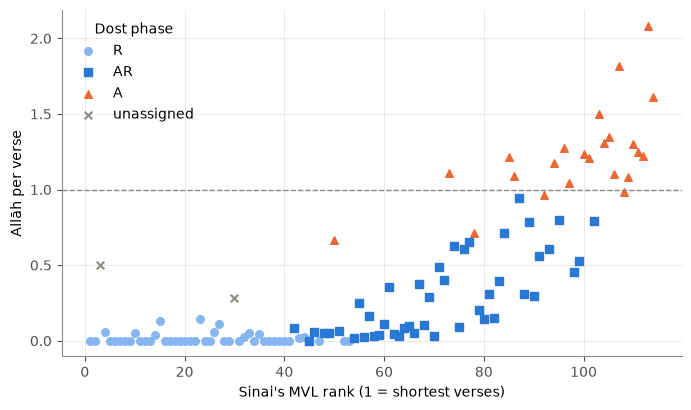

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
colors = {"R": "#86b6ef", "AR": "#2a78d6", "A": "#eb6834", "unassigned": "#8a8984"}
markers = {"R": "o", "AR": "s", "A": "^", "unassigned": "x"}
for ph in colors:
    g = t[t.dost_phase.astype(str) == ph]
    ax.scatter(g.sinai_mvl_rank, g.allah_per_verse, c=colors[ph], marker=markers[ph], s=30, label=ph)
ax.axhline(1, color="#8a8984", ls="--", lw=1)
ax.set_xlabel("Sinai's MVL rank (1 = shortest verses)"); ax.set_ylabel("Allāh per verse")
style_axes(ax); ax.legend(frameon=False, title="Dost phase");

In [9]:
t[(t.dost_phase == "A") & (t.allah_per_verse < 1)][["name_translit", "allah", "n_verses_used", "allah_per_verse", "dost_note"]]

,name_translit,allah,n_verses_used,allah_per_verse,dost_note
surah,,,,,
2,Al-Baqara,282,286,0.986014,"A-Qur'an, but opening section likely from AR p..."
22,Al-Hajj,75,78,0.961538,A-Qur'an despite MVL rank
47,Muhammad,27,38,0.710526,A-Qur'an despite MVL rank
110,An-Nasr,2,3,0.666667,"A-Qur'an despite short verses: fatḥ = victory,..."


No AR surah reaches one *Allāh* per verse; 19 of the 23 A surahs do. Of the four exceptions, 2 and 22 sit just below the line (0.99 and 0.96). 47 and 110 are well below it (about 0.7), and Dost places them in the A-Qur'an on other grounds: in 47, *Allāh* outnumbers *Rabb-X* 27 to 4; in 110, *fatḥ* means "victory" and *dīn* means "religion", as in the late surahs.

**Question 5.3.** Is it a problem that Dost *chose* the threshold after looking at the data? How would you test the rule fairly? (One answer: fix the threshold now, and apply it to a text or a set of passages he did not look at, such as Bazargan's blocks.)

## 5.5 The real test: take the names away

Dost defined the phases with divine names, so of course divine names separate them. The interesting question is whether **everything else** does too. We remove *Allāh*, *rabb* and *al-Raḥmān* from every verse, train a classifier on the remaining lemmas, and predict each surah's phase without the model ever seeing that surah.

In [10]:
pred, confusion = dn.phase_classifier(remove_divine_names=True)
confusion

model says,R,AR,A
Dost says,,,
R,38,6,0
AR,3,41,1
A,1,0,22


In [11]:
pred[pred.predicted != pred.dost_phase][["dost_phase", "predicted", "R", "AR", "A"]].round(2)

,dost_phase,predicted,R,AR,A
surah,,,,,
52,AR,R,0.47,0.41,0.13
54,R,AR,0.37,0.54,0.08
55,AR,R,0.74,0.23,0.04
68,R,AR,0.41,0.47,0.12
76,AR,R,0.55,0.34,0.11
98,AR,A,0.18,0.29,0.53
106,R,AR,0.34,0.43,0.23
109,R,AR,0.30,0.36,0.34
110,A,R,0.45,0.27,0.28


About 90% of surahs are put in Dost's phase from vocabulary alone, with divine names removed. So the three phases are not just naming habits: other words change at the same boundaries, as Dost argues from *nabī*, *ṣirāṭ*, *tawrāt* and the rest. Most misses sit on the R/AR boundary, and most are short surahs with very little text.

**Question 5.4.** Surah 55 (al-Raḥmān) is predicted R, while Dost puts it among the first Raḥmān surahs (AR). It is also one of the four surahs Cairo and Nöldeke disagree about. What does its case tell you about the R/AR boundary?

**Question 5.5.** Dost's project also uses *foreign vocabulary*. Pick three words Jeffery (1938) lists as loanwords, e.g. *ṣirāṭ*, *faṭara* or *ḥizb*, and find their lemmas in `load_morphology()`. In which phases do they occur?